In [1]:
# External modules (to "pip install")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate
from scipy.optimize import curve_fit
# Modules from Standard lib
from pathlib import Path

# RadioBio module
import radiopyo as rp

import time

In [14]:
file = Path(rf"Configuration_Bordet_Emballement.toml")
uc = rp.UnitCell.from_toml(file)
uc.set_beam("UHDR")
O2 = uc.env.species.get("O2")

PERIOD = 1200 # seconds


res = uc.prepare_chunked_run([1e-9, PERIOD],
                             max_step_size_on=1e-4,
                             max_step_size_off=0.5,
                            # max_step_size_final=0.5,
                            #atol=1e-2,
                            #rtol=1e-2,
                            ).run()


df_UHDR= res.to_pandas()


2026-11-11 17:44:36,393::radiopyo::INFO::NINA ---------------Loading config from file: Configuration_Bordet_Emballement.toml
2026-11-11 17:44:36,396::radiopyo::INFO::Resolving include: C:\Users\blond\Desktop\radiopyo\radiopyo\data\config_Labarbe.toml
2026-11-11 17:44:36,398::radiopyo::INFO::Resolving include: C:\Users\blond\Desktop\radiopyo\radiopyo\data\basic_water_radiolysis.toml
2026-11-11 17:44:36,519::radiopyo::INFO::Resolving include: C:\Users\blond\Desktop\radiopyo\radiopyo\data\reactions_biology.toml
2026-11-11 17:44:36,571::radiopyo::WARNING::Unable to compute mass of GSH. Setting it to default mass, i.e. 0
2026-11-11 17:44:36,725::radiopyo::WARNING::Unable to compute mass of GSH. Setting it to default mass, i.e. 0
2026-11-11 17:44:36,824::radiopyo::INFO::File is loaded
2026-11-11 17:44:36,824::radiopyo::INFO::Beam configuration detected in config file
2026-11-11 17:44:36,825::radiopyo::INFO::BEAM:: Found beam 'conv' as pulsed -> {'dose_rate': 0.16, 'period': 0.033333333333333

  0%|          | 0/8 [00:00<?, ?it/s]

C:\Users\blond\.conda\envs\New\Lib\site-packages\scipy\integrate\_ivp\lsoda.py:161: UserWarning: lsoda: Repeated convergence failures (perhaps bad Jacobian or tolerances).
  solver._y, solver.t = integrator.run(


2026-11-11 17:45:26,261::radiopyo::INFO::Simulation done!


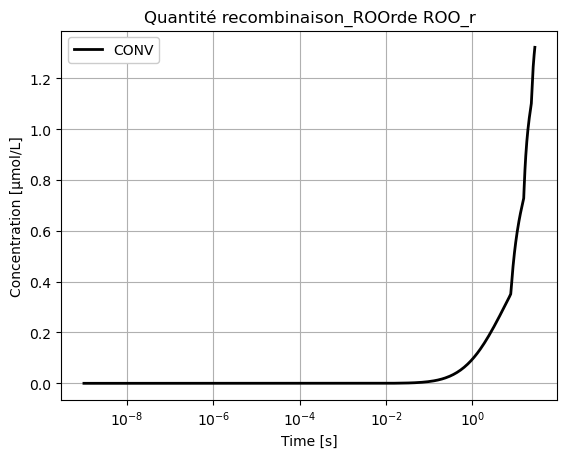

In [15]:
G_species = ["ROOH"]
fig, ax = plt.subplots()
for label in G_species:
    ax.plot(df_UHDR.index, df_UHDR['ROOH'], label='CONV', marker="", linewidth=2, linestyle='-', color='black')
   

#ax.set_xlim([1e-8,2000])

ax.set_xscale("log")
#ax.set_yscale("log")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Concentration [µmol/L]")
ax.legend(fancybox=True, framealpha=1)
ax.set_title("Quantité recombinaison_ROOrde ROO_r")
ax.grid()
